# 02 · Who subscribes? Exploratory analysis
**Question:** where is subscription rate meaningfully different, and is the gap big enough to act on?

In [1]:
import sys, json; sys.path.insert(0, '..')
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from IPython.display import Image, display
from src import data, modelling, business, segmentation
from src.config import *
pd.set_option('display.width', 200); pd.set_option('display.float_format', '{:.3f}'.format)
df = data.clean(data.load_raw())

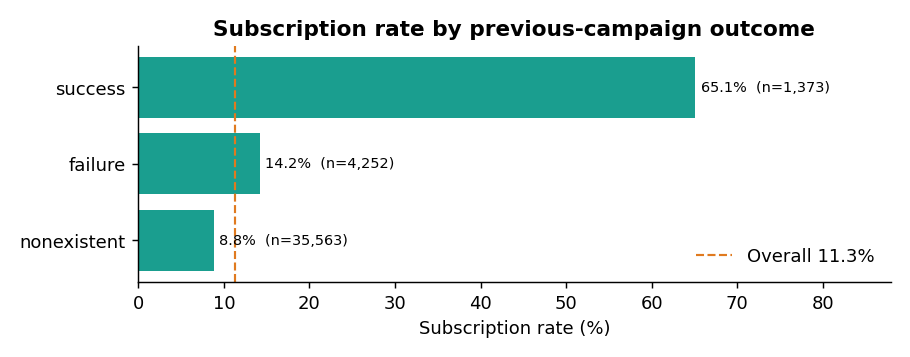

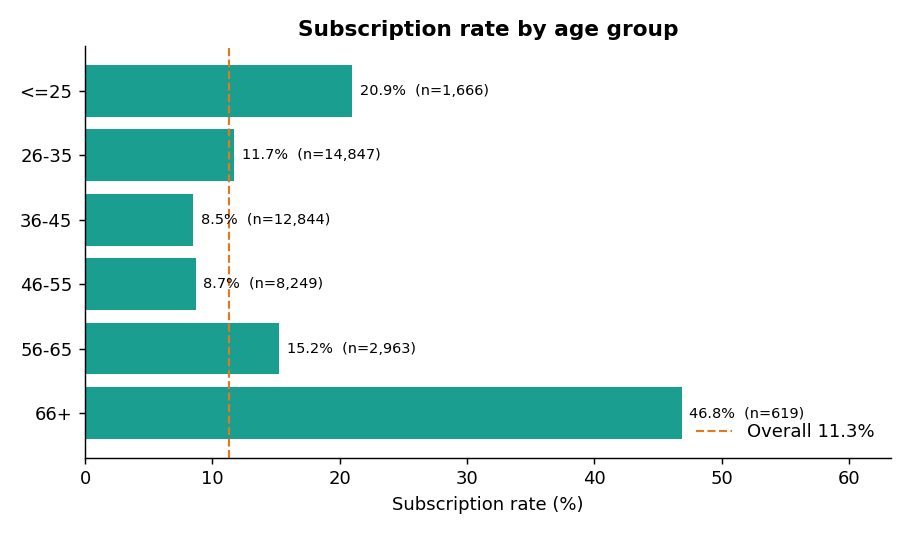

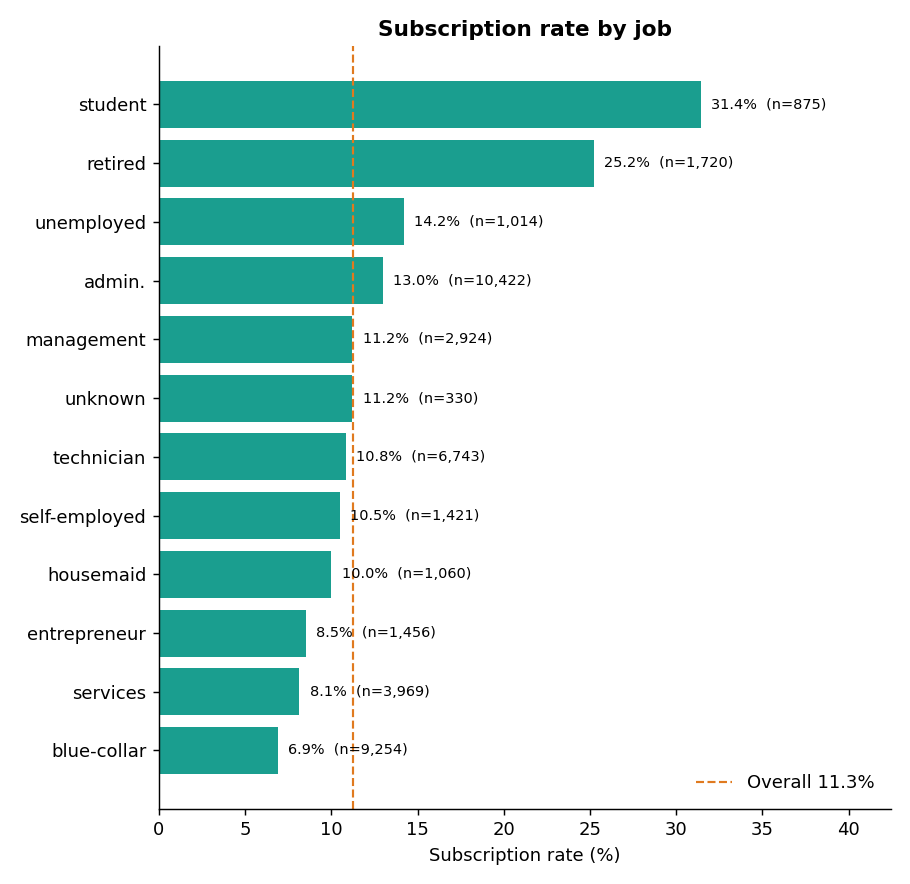

In [2]:
for f in ['subscription_rate_by_prior_outcome','subscription_rate_by_age','subscription_rate_by_job']:
    display(Image(IMAGES/f'{f}.png', width=560))

**Findings**
- Customers with a *previous successful* campaign convert at ~65% vs 9% for first-time prospects: the single strongest signal in the data.
- Subscription rate is U-shaped by age: ≤25 and 56+ convert at roughly 2× (≤25) to 5× (66+) the 36–55 core. Students and retirees lead by job.
- The pattern of retired/student/66+ is consistent: customers with *time and savings* intent respond best.

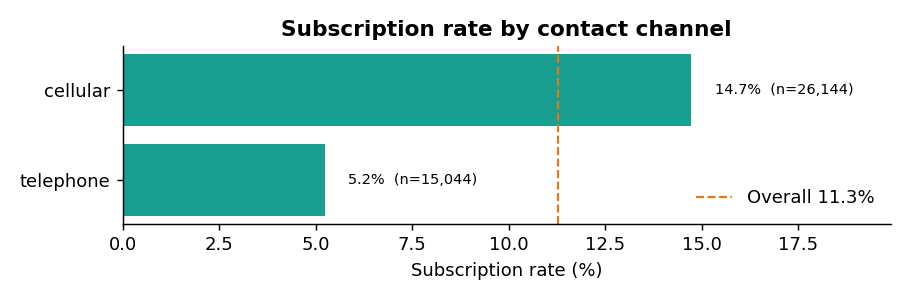

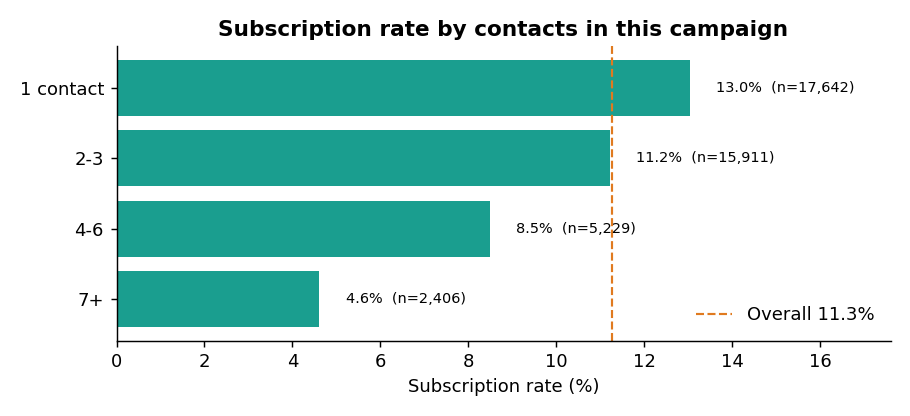

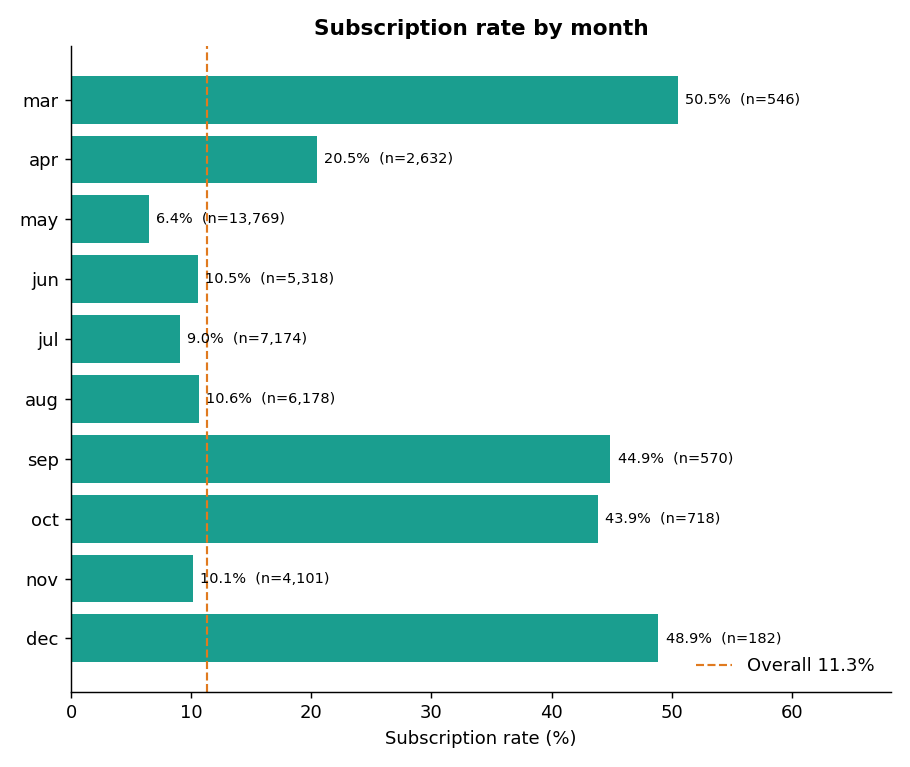

In [3]:
for f in ['subscription_rate_by_contact','subscription_rate_by_intensity','subscription_rate_by_month']:
    display(Image(IMAGES/f'{f}.png', width=560))

**Findings**
- Cellular beats landline in **every** age group (SQL query 04), so it is not just an age-mix effect. It is also higher in 6 of the 7 campaign periods where both channels were used, but the gap shrinks once period is held constant (about 18.6% vs 13.2%, period-adjusted, against 14.7% vs 5.2% pooled; `data/processed/contact_by_period.csv`).
- Customers whose campaign ended after 1 call converted at 13.0%; those whose campaign reached 10+ calls converted at 3.6%. This compares *final* call counts, and customers who say yes stop being called, so it is not the conversion rate of the 10th call itself.
- Months with the highest rates (Mar, Sep, Oct, Dec) are also the smallest-volume months. This is likely a *selection effect* (warm contacts called in quieter periods), not proof that those months cause higher conversion.

**Caveat:** channel and month are confounded with calendar period (landline calls cluster early in the campaign). These are patterns to test, not causal claims.

In [4]:
print(pd.crosstab(df.contact, df.campaign_order // 8000, normalize='index').round(2).rename(columns=lambda c: f'period {c+1}'))

campaign_order  period 1  period 2  period 3  period 4  period 5  period 6
contact                                                                   
cellular           0.000     0.120     0.290     0.280     0.270     0.040
telephone          0.530     0.320     0.030     0.050     0.060     0.010
